<b>Comparing streams from KRIOS (Cook et al., 2025), NBODY6++GPU, and Particle Spray</b>

The load_data script contains functions relevant to loading each dataset. There is an environment.yml file in this directory that should provide a Conda environment suitable for running this notebook.

In [12]:
import matplotlib.pyplot as plt

import astropy.coordinates as coord

_ = coord.galactocentric_frame_defaults.set("v4.0")

import warnings

warnings.filterwarnings("ignore")

from load_data import (
    load_krios_snapshot_data,
    load_krios_run_data,
    load_ps_data,
    load_nbody_run_data,
    load_nbody_snapshot_data,
)

BASE_DIR = "/path/to/krios_ii_paper_supplement/"
JOB_ID = 20613092
TIMESTAMP = 5000.00000000

The data for each stream model is collated into a Pandas DataFrame object named *_stream_particle_data here:

In [21]:
krios_run_data = load_krios_run_data(BASE_DIR + "snapshot_data/krios_data/")
krios_snapshot_data = load_krios_snapshot_data(
    BASE_DIR + "snapshot_data/krios_data/", JOB_ID, TIMESTAMP
)
krios_stream_particle_data = krios_snapshot_data["particle_data"][
    krios_snapshot_data["particle_data"]["is_stream"]
]

nbody_run_data = load_nbody_run_data(BASE_DIR + "snapshot_data/nbody_data/")
nbody_snapshot_data = load_nbody_snapshot_data(BASE_DIR + "snapshot_data/nbody_data/")
nbody_stream_particle_data = nbody_snapshot_data[nbody_snapshot_data["is_stream"]]

ps_stream_particle_data = load_ps_data(BASE_DIR + "snapshot_data/ps_data/")

It is worth noting that these datasets contain more than is displayed here for illustrative purposes, and the authors encourage exploring each stream model in more detail. The next cell plots each stream in the great-circle coordinate system, where the $N$-body and particle-spray streams are offset in $\phi_{2}$ for clarity:

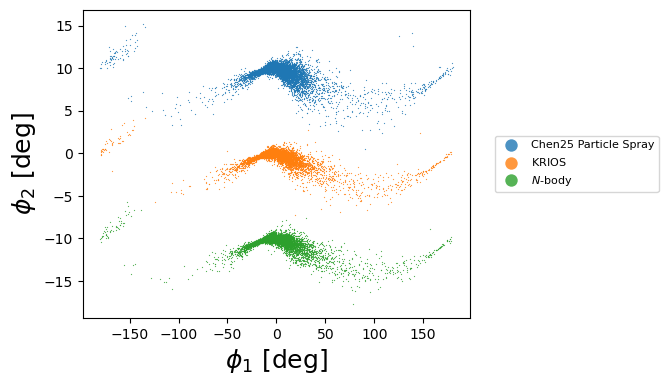

In [22]:
plt.figure(figsize=(5,4))

plt.scatter(
    ps_stream_particle_data["phi1"],
    ps_stream_particle_data["phi2"] + 10.0,
    s=0.8,
    alpha=0.8,
    edgecolors=None,
    linewidths=0,
    label="Chen25 Particle Spray",
    rasterized=True,
)
plt.scatter(
    krios_stream_particle_data["phi1"],
    krios_stream_particle_data["phi2"],
    s=0.8,
    alpha=0.8,
    edgecolors=None,
    linewidths=0,
    label=r"$\mathsf{KRIOS}$",
    rasterized=True,
)
plt.scatter(
    nbody_stream_particle_data["phi1"],
    nbody_stream_particle_data["phi2"] - 10.0,
    s=0.8,
    alpha=0.8,
    edgecolors=None,
    linewidths=0,
    label=r"$N$-body",
    rasterized=True,
)

plt.xlabel(r"$\phi_{1}$ [deg]", fontsize=18)
plt.ylabel(r"$\phi_{2}$ [deg]", fontsize=18)
plt.legend(loc="center left", bbox_to_anchor=(1.05, 0.5), markerscale=10, fontsize=8)

The next plot shows the integrals of motion ($L_{z'}$ and $E$) for each stream particle, where again the $N$-body and particle-spray models are artificially offset:

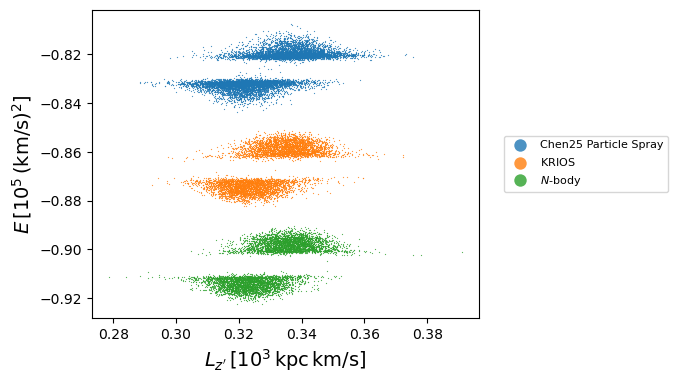

In [23]:
plt.figure(figsize=(5,4))

plt.scatter(
    ps_stream_particle_data["L_z"],
    ps_stream_particle_data["E_wrt_host"] + 0.04,
    s=0.8,
    alpha=0.8,
    edgecolors=None,
    linewidths=0,
    label="Chen25 Particle Spray",
    rasterized=True,
)
plt.scatter(
    krios_stream_particle_data["L_z"],
    krios_stream_particle_data["E_wrt_host"],
    s=0.8,
    alpha=0.8,
    edgecolors=None,
    linewidths=0,
    label=r"$\mathsf{KRIOS}$",
    rasterized=True,
)
plt.scatter(
    nbody_stream_particle_data["L_z"],
    nbody_stream_particle_data["E_wrt_host"] - 0.04,
    s=0.8,
    alpha=0.8,
    edgecolors=None,
    linewidths=0,
    label=r"$N$-body",
    rasterized=True,
)

plt.xlabel(r"$L_{z'}\, [10^{3}\,{\rm kpc\,km/s}]$", fontsize=14)
plt.ylabel(r"$E\, [10^{5}\,({\rm km/s})^{2}]$", fontsize=14)
plt.legend(loc="center left", bbox_to_anchor=(1.05, 0.5), markerscale=10, fontsize=8)